In [55]:
import pandas as pd
import matplotlib.pyplot as plt

In [56]:
results = pd.read_csv("results/naiveBayes_scores.csv")

# one row per feature pair and noise level, averaging over the 5 seeds
avg = results.groupby(["Feature 1", "Feature 2", "Noise Level"], as_index=False)[["Information Loss", "Extra Error", "Dependence"]].mean()

print(len(results), "rows ->", len(avg), "rows")
avg.head()

2275 rows -> 455 rows


,Feature 1,Feature 2,Noise Level,Information Loss,Extra Error,Dependence
0,age,capital-gain,0.0,-0.000530,-0.000307,0.006770
1,age,capital-gain,0.1,-0.002763,-0.000246,0.009507
2,age,capital-gain,0.2,-0.001732,-0.000246,0.011929
3,age,capital-gain,0.3,-0.000414,-0.000467,0.013640
4,age,capital-gain,0.4,0.000447,-0.004459,0.014575


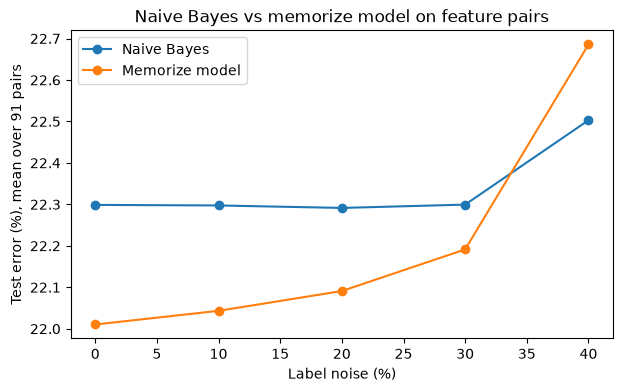

In [57]:
# mean over the 91 pairs, per noise level: the gap between the two lines is the extra error
means = results.groupby("Noise Level")[["Error Rate", "Memorize Error"]].mean()

plt.figure(figsize=(7, 4))
plt.plot(means.index * 100, means["Error Rate"] * 100, marker="o", label="Naive Bayes")
plt.plot(means.index * 100, means["Memorize Error"] * 100, marker="o", label="Memorize model")

plt.xlabel("Label noise (%)")
plt.ylabel("Test error (%), mean over 91 pairs")
plt.title("Naive Bayes vs memorize model on feature pairs")
plt.legend()
plt.show()

On average Naive Bayes is only ~0.3% worse (22.3% vs 22.0%) than the memorize model, so assuming independence costs little. At 40% noise the memorize model degrades more and the gap flips.

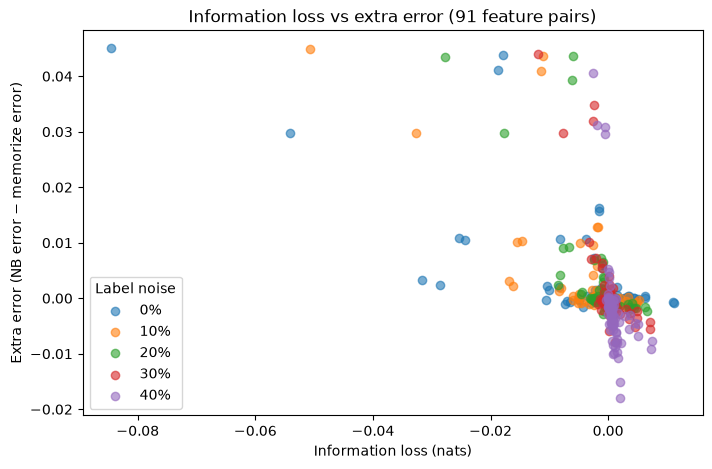

In [58]:
plt.figure(figsize=(8, 5))

for noise in avg["Noise Level"].unique():               # one color per noise level
    subset = avg[avg["Noise Level"] == noise]           # only the rows of this noise level
    plt.scatter(subset["Information Loss"], subset["Extra Error"], label=f"{noise:.0%}", alpha=0.6)

plt.xlabel("Information loss (nats)")
plt.ylabel("Extra error (NB error − memorize error)")
plt.title("Information loss vs extra error (91 feature pairs)")
plt.legend(title="Label noise")
plt.show()

All the dots with extra error above 0.01 have negative information loss, while the dots with positive information loss never exceed 0.005 (the opposite of Rish's claim).

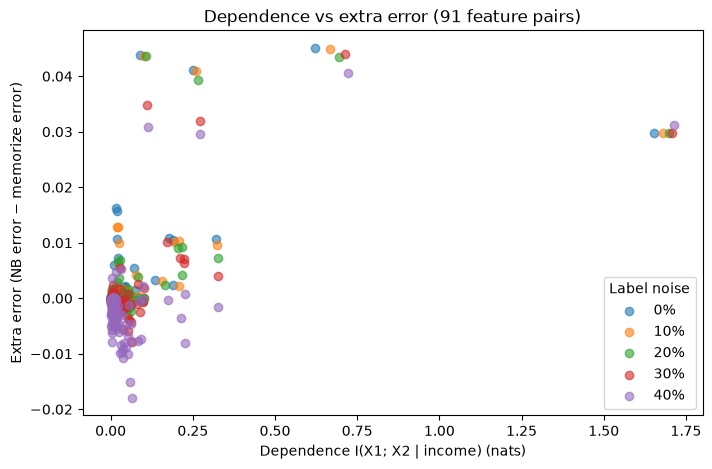

In [59]:
plt.figure(figsize=(8, 5))

for noise in avg["Noise Level"].unique():               # one color per noise level
    subset = avg[avg["Noise Level"] == noise]           # only the rows of this noise level
    plt.scatter(subset["Dependence"], subset["Extra Error"], label=f"{noise:.0%}", alpha=0.6)

plt.xlabel("Dependence I(X1; X2 | income) (nats)")
plt.ylabel("Extra error (NB error − memorize error)")
plt.title("Dependence vs extra error (91 feature pairs)")
plt.legend(title="Label noise")
plt.show()

More dependent pairs tend to have a higher extra error, but many still cost almost nothing.

In [60]:
# Spearman correlation with extra error, per noise level: which measure predicts it better?
rows = []
for noise in avg["Noise Level"].unique():
    subset = avg[avg["Noise Level"] == noise]
    rows.append({
        "Noise Level": f"{noise:.0%}",
        "Information Loss": subset["Information Loss"].corr(subset["Extra Error"], method="spearman"),
        "Dependence": subset["Dependence"].corr(subset["Extra Error"], method="spearman"),
    })

spearman = pd.DataFrame(rows)
spearman.round(2)

,Noise Level,Information Loss,Dependence
0,0%,-0.38,0.36
1,10%,-0.58,0.27
2,20%,-0.59,0.18
3,30%,-0.60,0.06
4,40%,-0.74,-0.15


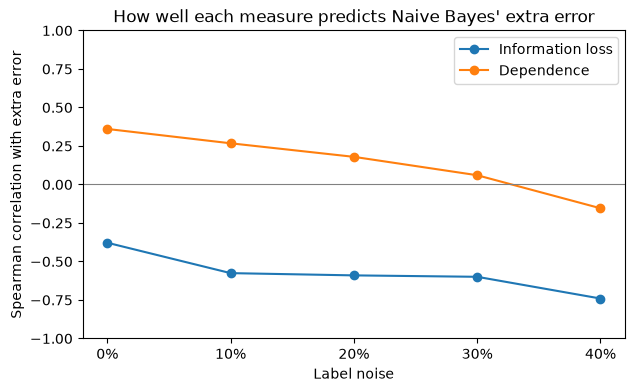

In [61]:
plt.figure(figsize=(7, 4))

plt.plot(spearman["Noise Level"], spearman["Information Loss"], marker="o", label="Information loss")
plt.plot(spearman["Noise Level"], spearman["Dependence"], marker="o", label="Dependence")
plt.axhline(0, color="gray", linewidth=0.8)       # above 0: predicts extra error, below: backwards

plt.ylim(-1, 1)
plt.xlabel("Label noise")
plt.ylabel("Spearman correlation with extra error")
plt.title("How well each measure predicts Naive Bayes' extra error")
plt.legend()
plt.show()

Spearman measures whether two things grow together, where 1 means they always do, 0 means no relation and −1 means one shrinks as the other grows. Dependence gets closest to 1 on clean labels but drops toward 0 with noise, while information loss stays below 0 at every noise level, the opposite of what Rish claims.

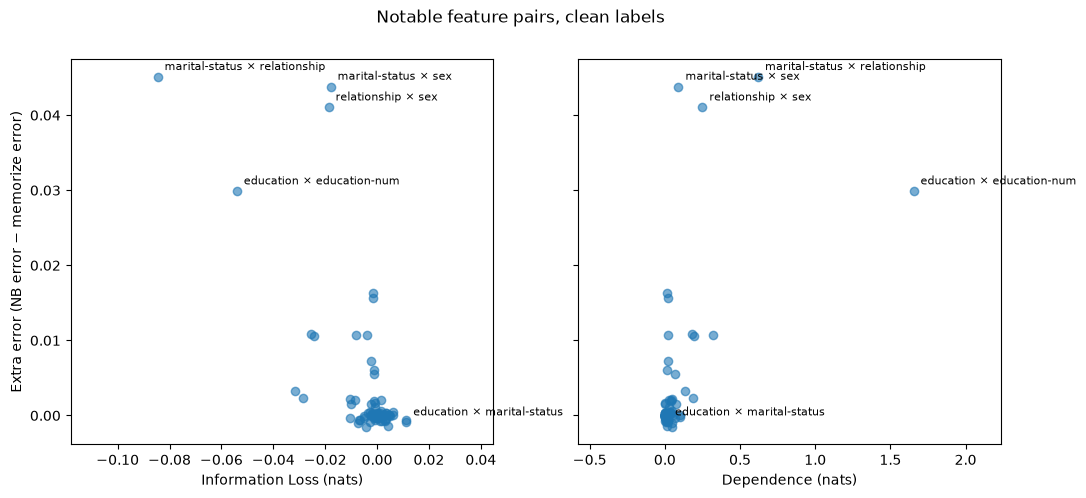

In [62]:
# clean labels only: name the 4 pairs with the most extra error and the one with the most information loss
clean = avg[avg["Noise Level"] == 0]
named = pd.concat([clean.nlargest(4, "Extra Error"), clean.nlargest(1, "Information Loss")])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, measure in zip(axes, ["Information Loss", "Dependence"]):
    ax.scatter(clean[measure], clean["Extra Error"], alpha=0.6)
    for _, row in named.iterrows():
        ax.annotate(f"{row['Feature 1']} × {row['Feature 2']}", (row[measure], row["Extra Error"]),
                    xytext=(5, 5), textcoords="offset points", fontsize=8)
    ax.margins(x=0.35)                                  # room for the labels on the right
    ax.set_xlabel(f"{measure} (nats)")

axes[0].set_ylabel("Extra error (NB error − memorize error)")
fig.suptitle("Notable feature pairs, clean labels")
plt.show()

Naive Bayes fails on pairs whose features partly repeat each other (e.g. marital-status × relationship), while the pair losing the most information (education × marital-status) costs nothing.

Rish's setting is very different from ours. His data was synthetic and he computed exact probabilities, while we estimate them from 32k real records. His problems are also designed around a dependence parameter, while in Adult the strongest dependencies come from features that partly repeat each other (e.g. relationship and marital-status). These differences might explain our results.
Rish also saw negative information loss and assumed it was harmless. On Adult, the pairs where Naive Bayes fails all have negative information loss, so his assumption may not hold on real data.